# Titanic: what decided who survived?

Two questions:
1. **Which factors influenced survival?** Answered first with plain exploratory analysis, then confirmed with model explanations (coefficients, feature importances and SHAP).
2. **How well can survival be predicted?** Logistic Regression as an interpretable baseline, compared with Random Forest and XGBoost, all evaluated on a held-out split and with repeated cross-validation.

Data: Kaggle *Titanic: Machine Learning from Disaster* (`data/train.csv`: 891 passengers with labels; `data/test.csv`: 418 without).

**Headline findings**
- **Sex was the biggest factor:** 74% of women survived against 19% of men. It accounts for 35% of what drives the model's predictions, about twice any other factor.
- **Wealth came next:** fare, class and cabin together make up another 35%. Survival rose from 20% in the cheapest fare quartile to 58% in the dearest, and from 24% in 3rd class to 63% in 1st.
- **The best model is the simplest:** Logistic Regression reaches **83.3% ± 2.2%** cross-validated accuracy. Random Forest and XGBoost land within that margin, and all three beat the "women survive" rule (78.7%).

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

import sys
sys.path.insert(0, '..')
from src.features import TitanicFeatures, extract_title

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
FIG = Path('../reports/figures')
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight'})

def save(fig, name):
    fig.savefig(FIG / f'{name}.png')

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
print(f'train {train.shape}, test {test.shape}; overall survival {train.Survived.mean():.1%}')

train (891, 12), test (418, 11); overall survival 38.4%


## 1. Exploratory analysis

Before any model: how does survival vary with sex, class, age and fare?

In [2]:
missing = pd.DataFrame({'train': train.isna().sum(), 'test': test.isna().sum()})
missing[(missing.train > 0) | (missing.test > 0)].assign(train_pct=lambda d: (d.train / len(train) * 100).round(1))

,train,test,train_pct
Age,177,86.0,19.9
Cabin,687,327.0,77.1
Embarked,2,0.0,0.2
Fare,0,1.0,0.0


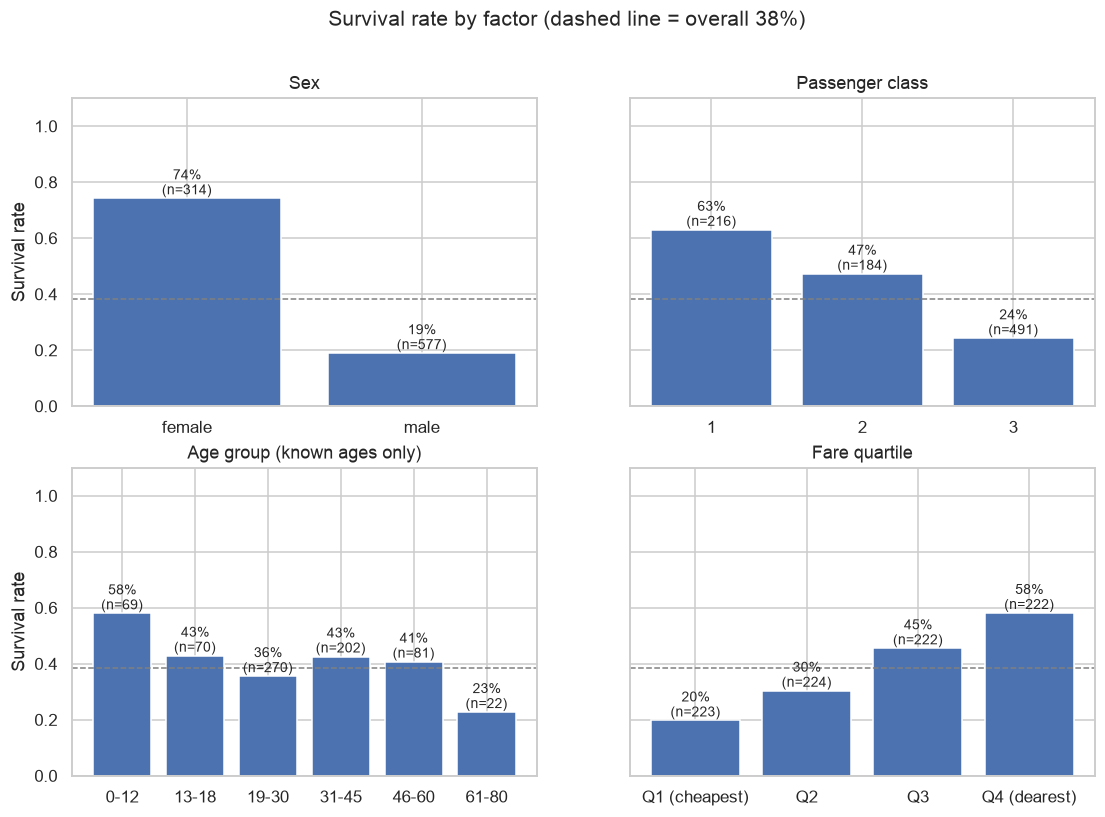

In [3]:
eda = train.assign(
    AgeGroup=pd.cut(train.Age, [0, 12, 18, 30, 45, 60, 80],
                    labels=['0-12', '13-18', '19-30', '31-45', '46-60', '61-80']),
    FareBand=pd.qcut(train.Fare, 4, labels=['Q1 (cheapest)', 'Q2', 'Q3', 'Q4 (dearest)']),
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, col, title in zip(axes.flat, ['Sex', 'Pclass', 'AgeGroup', 'FareBand'],
                          ['Sex', 'Passenger class', 'Age group (known ages only)', 'Fare quartile']):
    rates = eda.groupby(col, observed=True).Survived.agg(['mean', 'size'])
    bars = ax.bar(rates.index.astype(str), rates['mean'], color=sns.color_palette()[0])
    ax.bar_label(bars, labels=[f"{m:.0%}\n(n={n})" for m, n in zip(rates['mean'], rates['size'])], fontsize=9)
    ax.axhline(train.Survived.mean(), ls='--', c='grey', lw=1)
    ax.set(title=title, ylim=(0, 1.1), ylabel='Survival rate' if ax in axes[:, 0] else '')
fig.suptitle('Survival rate by factor (dashed line = overall 38%)', fontsize=14)
save(fig, '01_survival_by_factor'); plt.show()

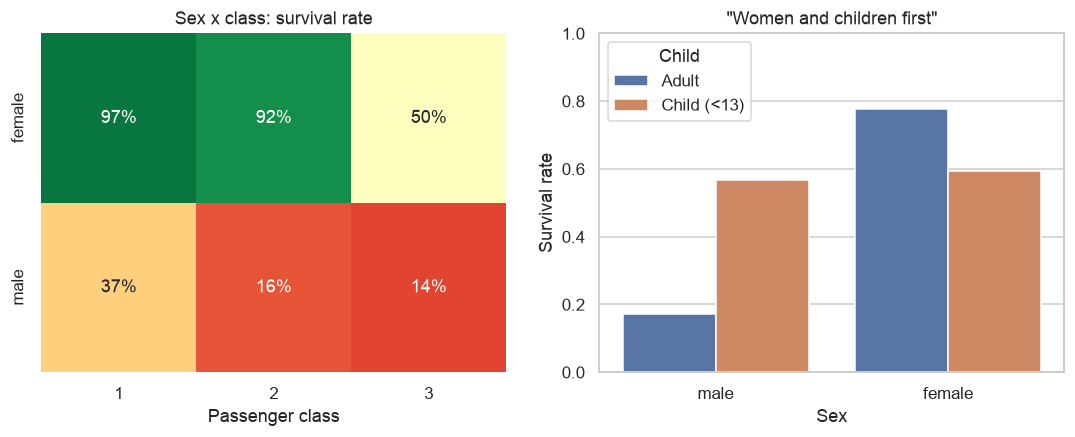

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pivot = train.pivot_table(index='Sex', columns='Pclass', values='Survived')
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='RdYlGn', vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set(title='Sex x class: survival rate', xlabel='Passenger class', ylabel='')

child = train.dropna(subset=['Age']).assign(Child=lambda d: np.where(d.Age < 13, 'Child (<13)', 'Adult'))
sns.barplot(data=child, x='Sex', y='Survived', hue='Child', errorbar=None, ax=axes[1])
axes[1].set(title='"Women and children first"', ylabel='Survival rate', ylim=(0, 1))
save(fig, '02_sex_class_children'); plt.show()

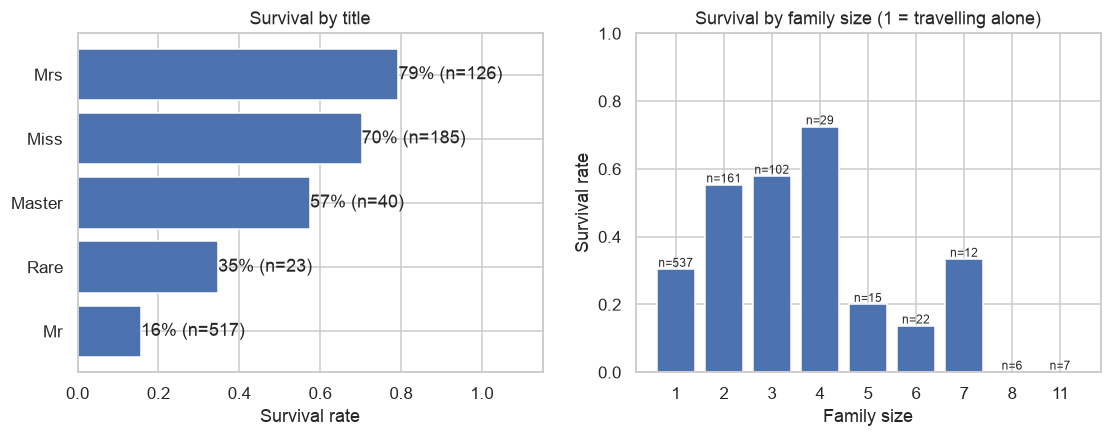

In [5]:
titles = train.assign(Title=train.Name.map(extract_title),
                      FamilySize=train.SibSp + train.Parch + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t = titles.groupby('Title').Survived.agg(['mean', 'size']).sort_values('mean')
bars = axes[0].barh(t.index, t['mean']); axes[0].bar_label(bars, labels=[f"{m:.0%} (n={n})" for m, n in zip(t['mean'], t['size'])])
axes[0].set(title='Survival by title', xlim=(0, 1.15), xlabel='Survival rate')
f = titles.groupby('FamilySize').Survived.agg(['mean', 'size'])
bars = axes[1].bar(f.index.astype(str), f['mean']); axes[1].bar_label(bars, labels=[f"n={n}" for n in f['size']], fontsize=8)
axes[1].set(title='Survival by family size (1 = travelling alone)', ylim=(0, 1), ylabel='Survival rate', xlabel='Family size')
save(fig, '03_title_family'); plt.show()

In [6]:
eda_summary = {
    'overall': train.Survived.mean(),
    'by_sex': train.groupby('Sex').Survived.mean().to_dict(),
    'by_class': train.groupby('Pclass').Survived.mean().to_dict(),
    'by_sex_class': {f'{s}, class {c}': v for (s, c), v in train.groupby(['Sex', 'Pclass']).Survived.mean().items()},
    'children_under_13': child[child.Age < 13].Survived.mean(),
    'by_family_size': titles.groupby(pd.cut(titles.FamilySize, [0, 1, 4, 11], labels=['alone', '2-4', '5+']), observed=True).Survived.mean().to_dict(),
    'by_fare_quartile': eda.groupby('FareBand', observed=True).Survived.mean().to_dict(),
}
pd.Series({k: v for k, v in eda_summary.items() if not isinstance(v, dict)}).map('{:.1%}'.format)

overall              38.4%
children_under_13    58.0%
dtype: str

## 2. Feature engineering

`src/features.py` turns the raw columns into model features. Every fill-in value is **learned in `fit()` from training data only**, so it can sit inside a scikit-learn pipeline without leaking test data:

| Feature | How it's built |
| --- | --- |
| `Title_*` | Mr / Mrs / Miss / Master / Rare, from the name (Mlle and Ms become Miss, Mme becomes Mrs) |
| `FamilySize`, `IsAlone` | SibSp + Parch + 1, and whether that is 1 |
| `Age`, `AgeWasMissing` | missing ages filled with the median **for that title and class** (a missing "Master" in 3rd class gets a boy's age, not the adult median) |
| `HasCabin`, `Deck_*` | cabin recorded or not, and deck grouped as ABC / DE / FG |
| `LogFare` | log(1 + fare), because fares are heavily skewed; the one missing fare in test.csv gets its class median |
| `Embarked_*` | the 2 missing ports filled with the most common one |
| `IsMale`, `Pclass` | as given |

In [7]:
features = TitanicFeatures().fit(train)
X_all = features.transform(train)
print(X_all.shape)
X_all.head()

(891, 19)


,Pclass,IsMale,Age,AgeWasMissing,FamilySize,IsAlone,LogFare,HasCabin,Deck_ABC,Deck_DE,Deck_FG,Title_Mr,Title_Mrs,Title_Miss,Title_Master,Title_Rare,Embarked_C,Embarked_Q,Embarked_S
0,3,1,22.0,0,2,0,2.110213,0,0,0,0,1,0,0,0,0,0,0,1
1,1,0,38.0,0,2,0,4.280593,1,1,0,0,0,1,0,0,0,1,0,0
2,3,0,26.0,0,1,1,2.188856,0,0,0,0,0,0,1,0,0,0,0,1
3,1,0,35.0,0,2,0,3.990834,1,1,0,0,0,1,0,0,0,0,0,1
4,3,1,35.0,0,1,1,2.202765,0,0,0,0,1,0,0,0,0,0,0,1


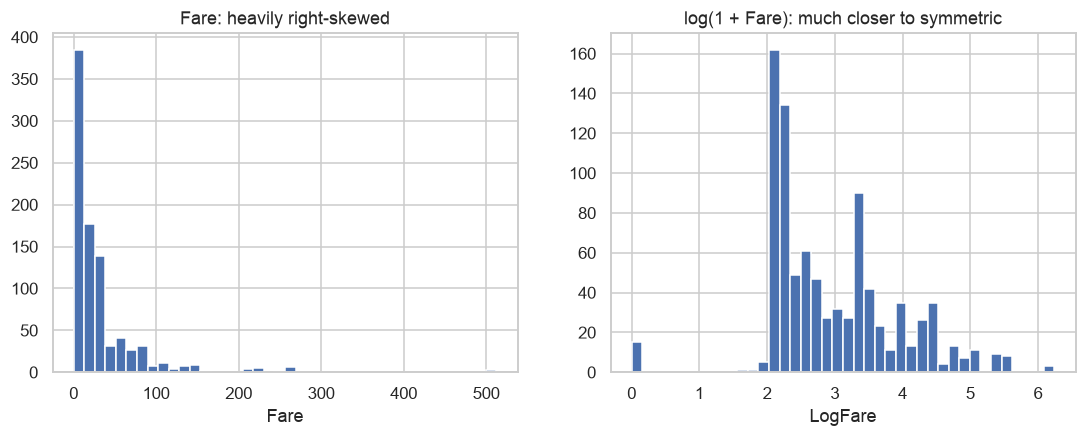

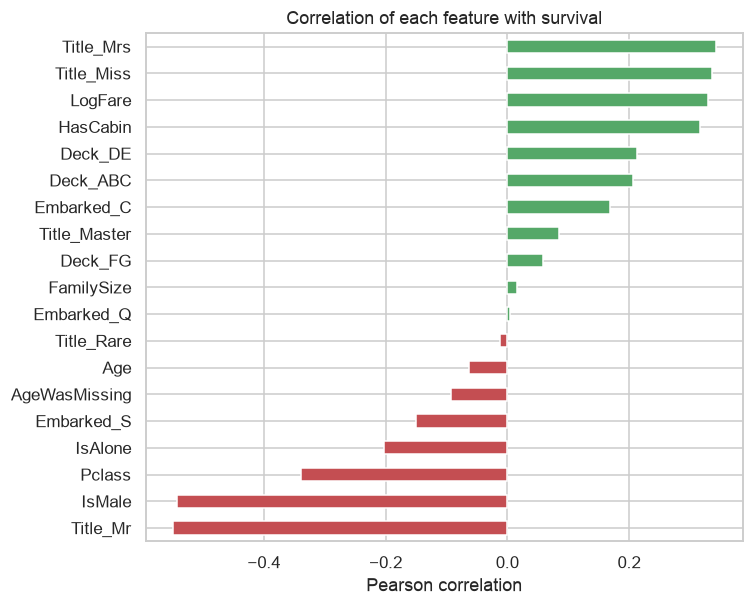

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train.Fare, bins=40); axes[0].set(title='Fare: heavily right-skewed', xlabel='Fare')
axes[1].hist(X_all.LogFare, bins=40); axes[1].set(title='log(1 + Fare): much closer to symmetric', xlabel='LogFare')
save(fig, '04_fare_log'); plt.show()

corr = X_all.assign(Survived=train.Survived).corr()['Survived'].drop('Survived').sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
corr.plot.barh(ax=ax, color=[sns.color_palette()[2] if v > 0 else sns.color_palette()[3] for v in corr])
ax.set(title='Correlation of each feature with survival', xlabel='Pearson correlation')
save(fig, '05_feature_correlation'); plt.show()

## 3. Models

A **stratified** 80/20 split keeps the ~38/62 survived/died ratio in both halves. Hyperparameters are tuned with 5-fold stratified cross-validation **on the training split only**, and the 20% test split is used once at the end. Each model is a pipeline, `TitanicFeatures` → (scaler for Logistic Regression) → classifier, so imputation is re-learned inside every fold.

Two baselines put the scores in context: always predicting "died", and the rule "women survive, men don't".

In [9]:
y = train.Survived
X_train, X_test, y_train, y_test = train_test_split(train, y, test_size=0.2, stratify=y, random_state=SEED)
print(f'train {len(X_train)} (survived {y_train.mean():.1%}), test {len(X_test)} (survived {y_test.mean():.1%})')

inner_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
candidates = {
    'Logistic Regression': (
        make_pipeline(TitanicFeatures(), StandardScaler(), LogisticRegression(max_iter=2000)),
        {'logisticregression__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    ),
    'Random Forest': (
        make_pipeline(TitanicFeatures(), RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1)),
        {'randomforestclassifier__max_depth': [4, 6, 8, None],
         'randomforestclassifier__min_samples_leaf': [1, 3, 5]},
    ),
    'XGBoost': (
        make_pipeline(TitanicFeatures(), XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='logloss',
                                                       subsample=0.8, colsample_bytree=0.8)),
        {'xgbclassifier__n_estimators': [150, 300, 500],
         'xgbclassifier__max_depth': [2, 3, 4],
         'xgbclassifier__learning_rate': [0.03, 0.1]},
    ),
}

models = {}
for name, (pipe, grid) in candidates.items():
    search = GridSearchCV(pipe, grid, cv=inner_cv, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
    models[name] = search.best_estimator_
    best = {k.split('__')[1]: v for k, v in search.best_params_.items()}
    print(f'{name:20} CV accuracy {search.best_score_:.3f}  best {best}')

train 712 (survived 38.3%), test 179 (survived 38.5%)


Logistic Regression  CV accuracy 0.832  best {'C': 0.3}


Random Forest        CV accuracy 0.834  best {'max_depth': 8, 'min_samples_leaf': 1}


XGBoost              CV accuracy 0.839  best {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500}


In [10]:
class WomenSurvive:
    # "Women survive, men don't" as a model, for comparison
    def fit(self, X, y): return self
    def predict(self, X): return (X.Sex == 'female').astype(int).to_numpy()
    def predict_proba(self, X):
        p = self.predict(X); return np.column_stack([1 - p, p])

baselines = {'Baseline: always "died"': DummyClassifier(strategy='most_frequent').fit(X_train, y_train),
             'Baseline: women survive': WomenSurvive()}

def scores(model, X, y_true):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred), 'f1': f1_score(y_true, pred), 'roc_auc': roc_auc_score(y_true, proba)}

holdout = pd.DataFrame({name: scores(m, X_test, y_test) for name, m in {**baselines, **models}.items()}).T
holdout.style.format('{:.3f}').highlight_max(axis=0, subset=pd.IndexSlice[list(models), :], color='#c7e9c0')

,accuracy,precision,recall,f1,roc_auc
"Baseline: always ""died""",0.615,0.000,0.000,0.000,0.500
Baseline: women survive,0.777,0.738,0.652,0.692,0.753
Logistic Regression,0.838,0.794,0.783,0.788,0.869
Random Forest,0.821,0.803,0.710,0.754,0.848
XGBoost,0.810,0.778,0.710,0.742,0.820


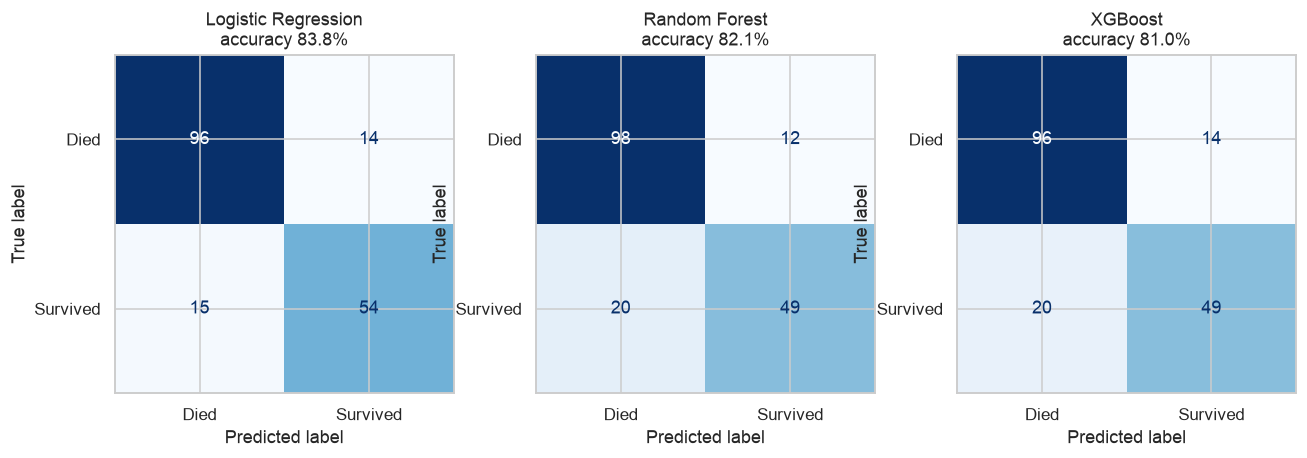

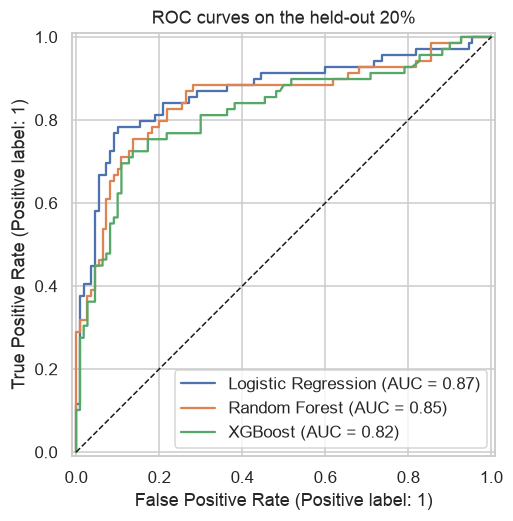

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['Died', 'Survived'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{name}\naccuracy {holdout.loc[name, "accuracy"]:.1%}')
save(fig, '06_confusion_matrices'); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_title('ROC curves on the held-out 20%')
save(fig, '07_roc_curves'); plt.show()

### Cross-validation: is the score a fluke?

The test split is only 179 passengers, so one unlucky split can swing accuracy by several points. Repeated stratified 5-fold cross-validation (5 folds x 5 repeats = 25 fits per model) on all 891 passengers gives a steadier estimate, with its spread.

,accuracy_mean,accuracy_std,f1_mean,f1_std
"Baseline: always ""died""",0.616,0.002,0.000,0.000
Baseline: women survive,0.787,0.026,0.710,0.037
Logistic Regression,0.833,0.022,0.780,0.029
Random Forest,0.824,0.020,0.758,0.026
XGBoost,0.829,0.023,0.769,0.030


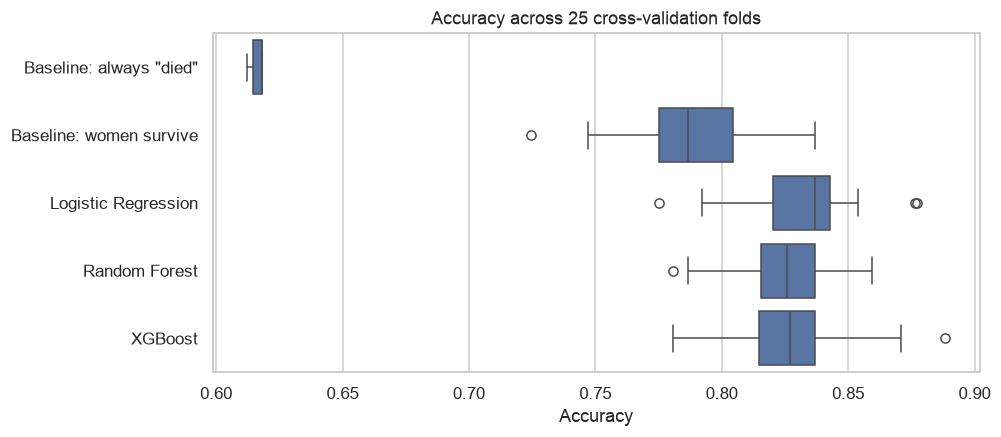

In [12]:
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
cv_rows, cv_raw = {}, {}
for name, model in {**baselines, **models}.items():
    if name == 'Baseline: women survive':
        folds = [accuracy_score(y.iloc[te], (train.Sex.iloc[te] == 'female').astype(int)) for _, te in outer_cv.split(train, y)]
        f1s = [f1_score(y.iloc[te], (train.Sex.iloc[te] == 'female').astype(int)) for _, te in outer_cv.split(train, y)]
        res = {'test_accuracy': np.array(folds), 'test_f1': np.array(f1s)}
    else:
        res = cross_validate(model, train, y, cv=outer_cv, scoring=['accuracy', 'f1'], n_jobs=-1)
    cv_raw[name] = res['test_accuracy']
    cv_rows[name] = {'accuracy_mean': res['test_accuracy'].mean(), 'accuracy_std': res['test_accuracy'].std(),
                     'f1_mean': res['test_f1'].mean(), 'f1_std': res['test_f1'].std()}
cv_table = pd.DataFrame(cv_rows).T
display(cv_table.style.format('{:.3f}'))

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=pd.DataFrame(cv_raw), orient='h', ax=ax, color=sns.color_palette()[0])
ax.set(title='Accuracy across 25 cross-validation folds', xlabel='Accuracy')
save(fig, '08_cv_accuracy'); plt.show()

### Where do the models go wrong?

Out-of-fold predictions from the tuned Logistic Regression, so every one of the 891 passengers is predicted by a model that never saw them:

In [13]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(models['Logistic Regression'], train, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
errors = train.assign(pred=oof, group=train.Sex + ', class ' + train.Pclass.astype(str))
error_table = errors.groupby('group').apply(lambda g: pd.Series({
    'passengers': len(g),
    'error rate': (g.pred != g.Survived).mean(),
    'missed survivors': ((g.Survived == 1) & (g.pred == 0)).sum(),
    'wrongly predicted to survive': ((g.Survived == 0) & (g.pred == 1)).sum(),
}), include_groups=False).sort_values('error rate', ascending=False)
error_table.style.format({'error rate': '{:.0%}', 'passengers': '{:.0f}', 'missed survivors': '{:.0f}', 'wrongly predicted to survive': '{:.0f}'})

,passengers,error rate,missed survivors,wrongly predicted to survive
group,,,,
"female, class 3",144,34%,4,45
"male, class 1",122,33%,27,13
"male, class 3",347,11%,37,0
"female, class 2",76,11%,2,6
"male, class 2",108,7%,8,0
"female, class 1",94,3%,0,3


## 4. What influenced survival? Model explanations

Three views that should agree if the story is real:
1. **Logistic Regression coefficients.** Features are standardised, so the sizes are comparable, and the sign gives the direction.
2. **Tree feature importances,** plus **permutation importance** on the held-out data (how much accuracy drops when a feature is shuffled), which is less biased toward high-cardinality features.
3. **SHAP values for XGBoost:** how much each feature pushed each passenger's predicted survival up or down.

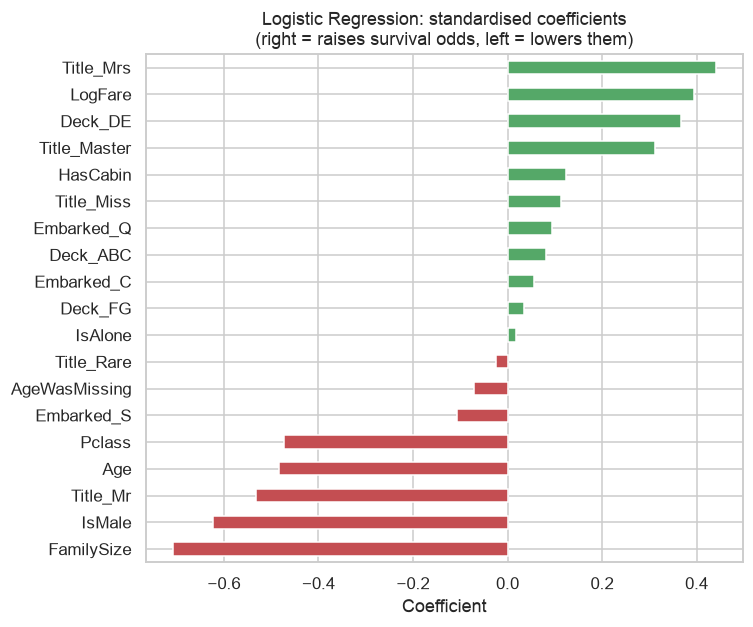

In [14]:
names = features.get_feature_names_out()
lr = models['Logistic Regression'][-1]
coef = pd.Series(lr.coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
coef.plot.barh(ax=ax, color=[sns.color_palette()[2] if v > 0 else sns.color_palette()[3] for v in coef])
ax.set(title='Logistic Regression: standardised coefficients\n(right = raises survival odds, left = lowers them)', xlabel='Coefficient')
save(fig, '09_logreg_coefficients'); plt.show()

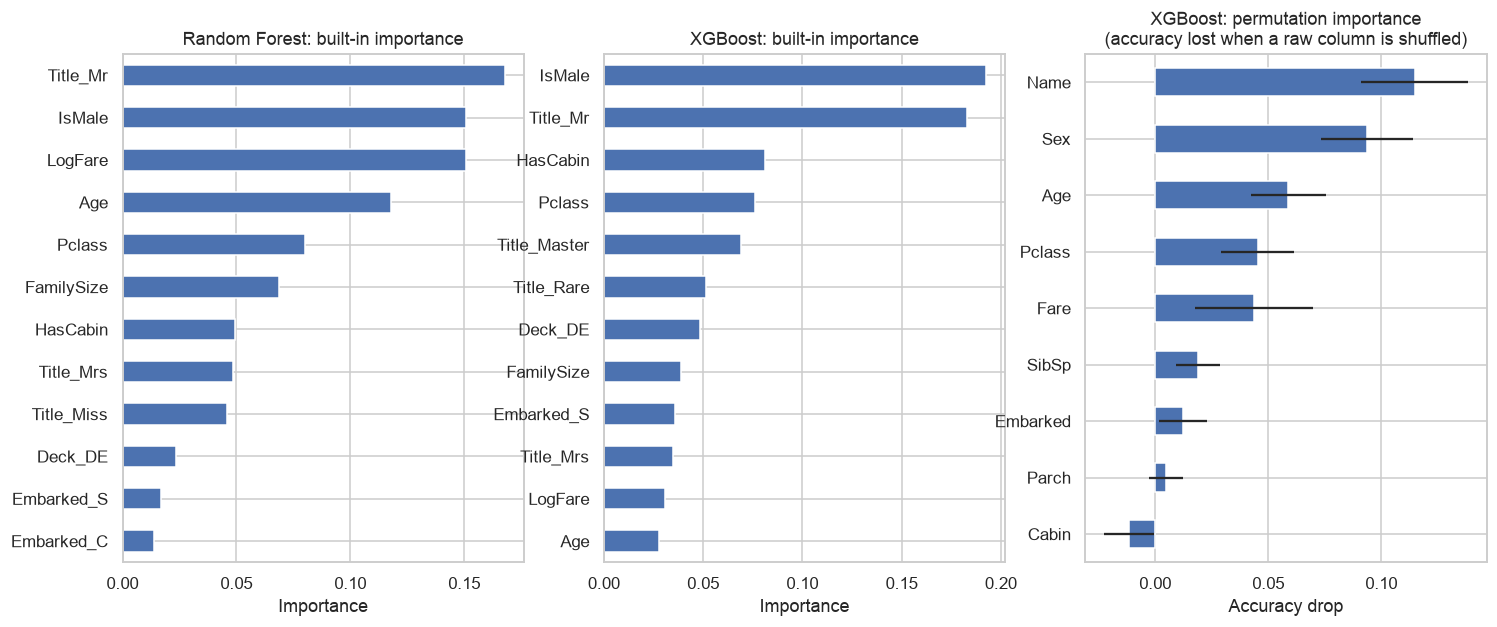

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, name in zip(axes[:2], ['Random Forest', 'XGBoost']):
    imp = pd.Series(models[name][-1].feature_importances_, index=names).sort_values().tail(12)
    imp.plot.barh(ax=ax); ax.set(title=f'{name}: built-in importance', xlabel='Importance')

perm = permutation_importance(models['XGBoost'], X_test, y_test, n_repeats=30, random_state=SEED, scoring='accuracy')
raw_cols = ['Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin', 'Embarked']
perm_s = pd.Series(perm.importances_mean, index=X_test.columns)[raw_cols].sort_values()
perm_s.plot.barh(ax=axes[2], xerr=pd.Series(perm.importances_std, index=X_test.columns)[perm_s.index])
axes[2].set(title='XGBoost: permutation importance\n(accuracy lost when a raw column is shuffled)', xlabel='Accuracy drop')
save(fig, '10_feature_importance'); plt.show()

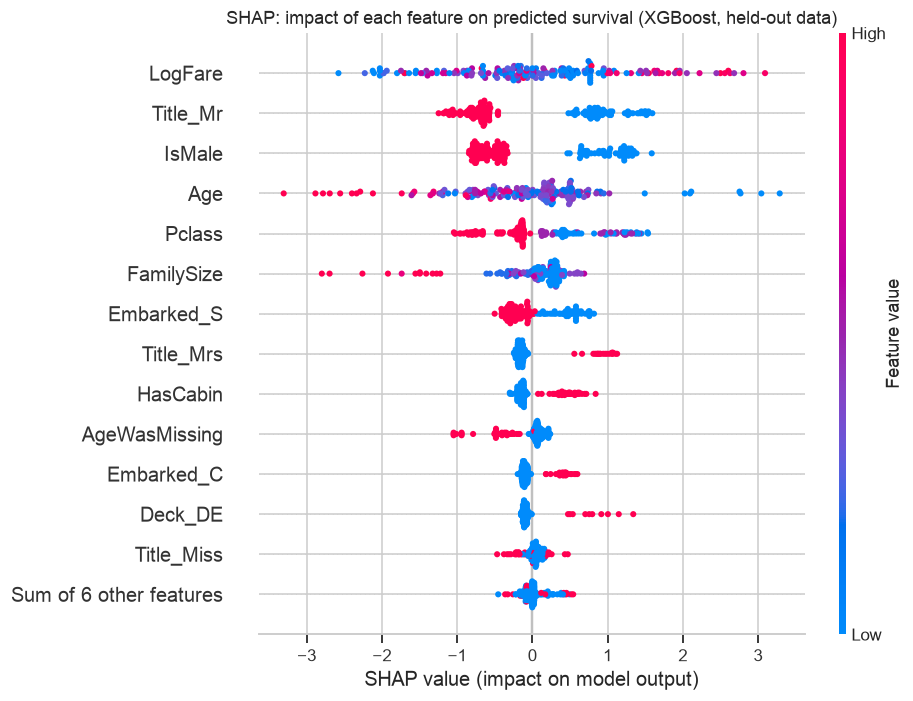

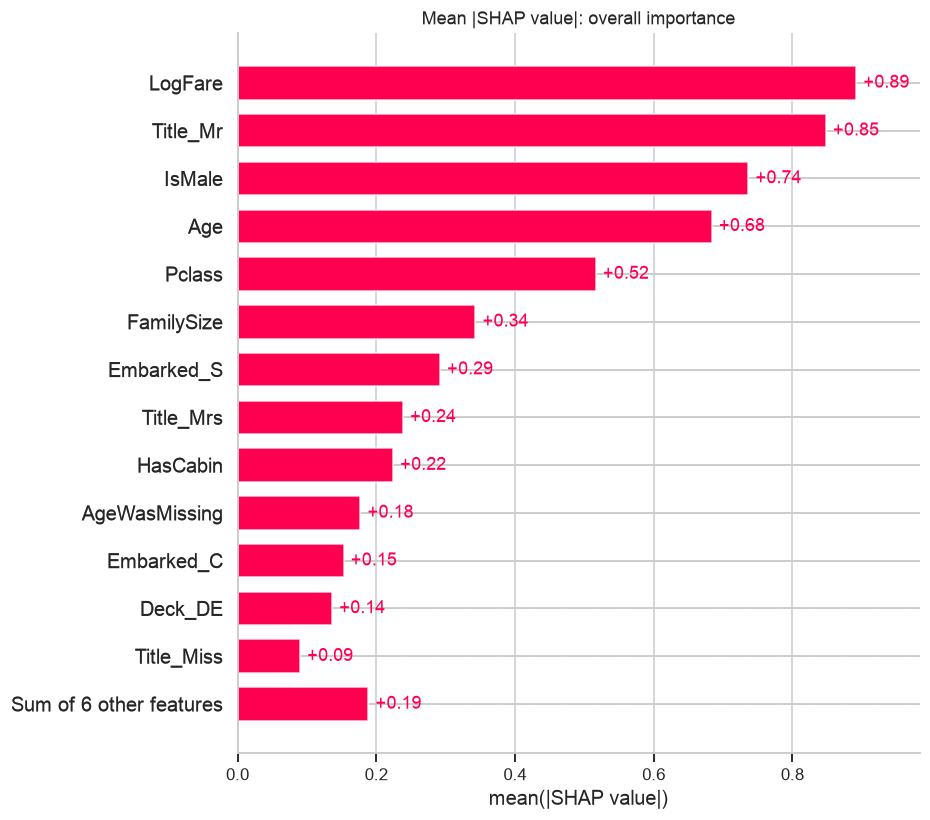

In [16]:
xgb_pipe = models['XGBoost']
X_test_feat = xgb_pipe[:-1].transform(X_test)
explainer = shap.TreeExplainer(xgb_pipe[-1])
shap_values = explainer(X_test_feat)

shap.plots.beeswarm(shap_values, max_display=14, show=False)
plt.title('SHAP: impact of each feature on predicted survival (XGBoost, held-out data)')
save(plt.gcf(), '11_shap_summary'); plt.show()

shap.plots.bar(shap_values, max_display=14, show=False)
plt.title('Mean |SHAP value|: overall importance')
save(plt.gcf(), '12_shap_importance'); plt.show()

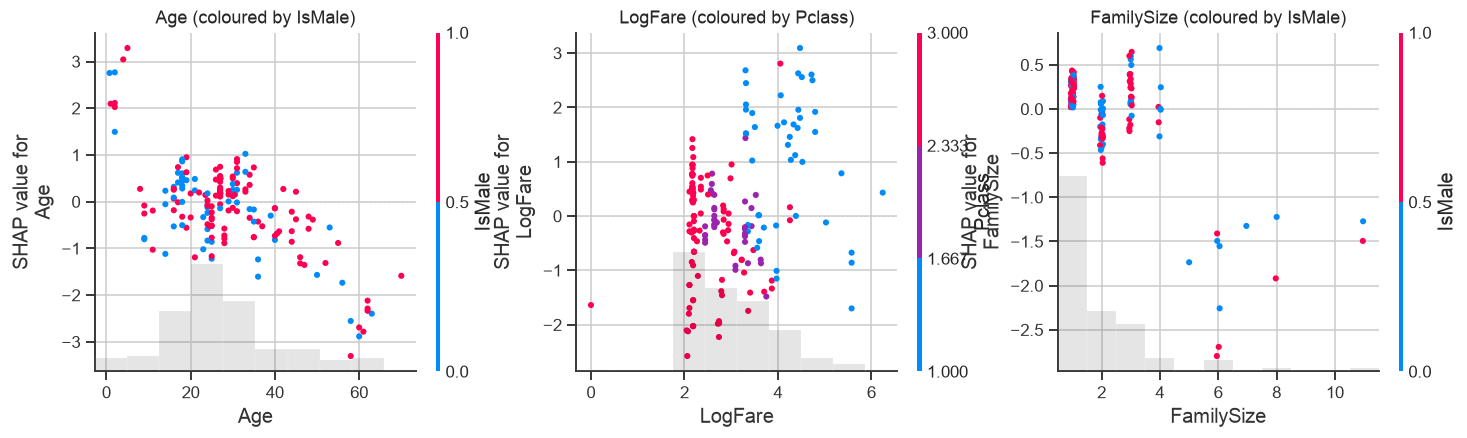

,mean_abs_shap,direction
LogFare,0.891876,higher value raises survival
Title_Mr,0.848148,higher value lowers survival
IsMale,0.736329,higher value lowers survival
Age,0.683641,higher value lowers survival
Pclass,0.516379,higher value lowers survival
FamilySize,0.342825,higher value lowers survival
Embarked_S,0.291761,higher value lowers survival
Title_Mrs,0.238369,higher value raises survival
HasCabin,0.224091,higher value raises survival
AgeWasMissing,0.177035,higher value lowers survival


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feat, color in zip(axes, ['Age', 'LogFare', 'FamilySize'], ['IsMale', 'Pclass', 'IsMale']):
    shap.plots.scatter(shap_values[:, feat], color=shap_values[:, color], ax=ax, show=False)
    ax.set_title(f'{feat} (coloured by {color})')
save(fig, '13_shap_dependence'); plt.show()

mean_abs = pd.Series(np.abs(shap_values.values).mean(0), index=names).sort_values(ascending=False)
direction = pd.Series([np.corrcoef(X_test_feat[c], shap_values[:, c].values)[0, 1] if X_test_feat[c].std() > 0 else 0
                       for c in names], index=names)
shap_table = pd.DataFrame({'mean_abs_shap': mean_abs, 'direction': direction[mean_abs.index].map(
    lambda r: 'higher value raises survival' if r > 0.1 else ('higher value lowers survival' if r < -0.1 else 'mixed / weak'))})
shap_table.head(10)

### Grouping correlated features

`IsMale`, `Title_Mr`, `Title_Mrs` and `Title_Miss` all carry the same sex signal, so SHAP spreads it across four columns and each one looks smaller than it really is. That's why `LogFare` tops the single-feature ranking above. Adding each passenger's SHAP values within a group gives that factor's **total** push on the prediction:

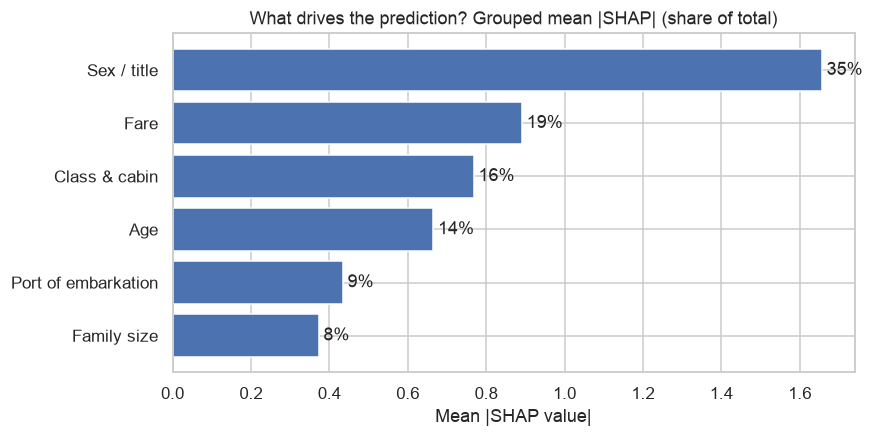

In [18]:
groups = {
    'Sex / title': ['IsMale'] + [c for c in names if c.startswith('Title_')],
    'Fare': ['LogFare'],
    'Class & cabin': ['Pclass', 'HasCabin'] + [c for c in names if c.startswith('Deck_')],
    'Age': ['Age', 'AgeWasMissing'],
    'Port of embarkation': [c for c in names if c.startswith('Embarked_')],
    'Family size': ['FamilySize', 'IsAlone'],
}
idx = {c: i for i, c in enumerate(names)}
grouped = pd.Series({g: np.abs(shap_values.values[:, [idx[c] for c in cols]].sum(1)).mean()
                     for g, cols in groups.items()}).sort_values()
share = grouped / grouped.sum()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(grouped.index, grouped.values)
ax.bar_label(bars, labels=[f'{s:.0%}' for s in share], padding=3)
ax.set(title='What drives the prediction? Grouped mean |SHAP| (share of total)', xlabel='Mean |SHAP value|')
save(fig, '14_shap_grouped'); plt.show()

## 5. Kaggle submission

The chosen model (best mean cross-validation accuracy) is refitted on all 891 labelled passengers and used to predict `test.csv`.

In [19]:
best_name = cv_table.loc[list(models)].accuracy_mean.idxmax()
final = candidates[best_name][0].set_params(**models[best_name].get_params()).fit(train, y)
submission = pd.DataFrame({'PassengerId': test.PassengerId, 'Survived': final.predict(test)})
submission.to_csv('../reports/submission.csv', index=False)
print(f'{best_name} -> reports/submission.csv ({len(submission)} rows, predicted survival {submission.Survived.mean():.1%})')

to_py = lambda d: {str(k): (to_py(v) if isinstance(v, dict) else float(v)) for k, v in d.items()}
metrics = {
    'holdout': to_py(holdout.to_dict(orient='index')),
    'cross_validation': to_py(cv_table.to_dict(orient='index')),
    'eda': to_py(eda_summary),
    'top_shap_features': to_py(mean_abs.head(10).to_dict()),
    'grouped_shap_share': to_py(share.sort_values(ascending=False).to_dict()),
    'chosen_model': best_name,
}
Path('../reports/metrics.json').write_text(json.dumps(metrics, indent=2))

Logistic Regression -> reports/submission.csv (418 rows, predicted survival 41.4%)


3603

## 6. Conclusions

### What influenced survival

The exploratory analysis and all three model explanations agree on the order:

1. **Sex / title (35% of the XGBoost explanation).** 74% of women survived against 19% of men. The Logistic Regression coefficients for `IsMale` (-0.62) and `Title_Mr` (-0.53) are among the most negative, and `Title_Mrs` (+0.44) the most positive. "Women and children first" really did shape outcomes.
2. **Wealth: fare (19%) plus class and cabin (16%).** Survival climbs steadily with fare quartile (20% → 30% → 45% → 58%) and class (63% / 47% / 24%). Class also changes what sex means: women in 1st and 2nd class survived at 97% and 92%, but women in 3rd class only at 50%. Men in 1st class (37%) did more than twice as well as men in 2nd or 3rd (16% and 14%).
3. **Age (14%).** Children under 13 survived at 58% against 38% overall, and the `Title_Master` coefficient (young boys, +0.31) is positive. In the SHAP dependence plot, older passengers are pushed toward lower survival.
4. **Family size (8%), and not in a straight line.** Passengers travelling alone survived at 30%, families of 2-4 at 58%, and families of 5 or more at only 16%. The Logistic Regression coefficient is simply negative (-0.71), whereas the tree models can capture the rise and then the fall.
5. **Port of embarkation (9%) is mostly a stand-in for class,** since Cherbourg had more 1st-class passengers. Treat it as a proxy, not a cause.

These are associations in the data, not causal effects. Fare, class and cabin overlap heavily, for example, so their individual shares shouldn't be over-interpreted.

### How well can survival be predicted

| | Cross-validated accuracy (25 folds) | Hold-out accuracy | Hold-out F1 | Hold-out ROC AUC |
| --- | --- | --- | --- | --- |
| Always "died" | 61.6% | 61.5% | 0.00 | 0.50 |
| Women survive | 78.7% ± 2.6 | 77.7% | 0.69 | 0.75 |
| **Logistic Regression** | **83.3% ± 2.2** | **83.8%** | **0.79** | **0.87** |
| Random Forest | 82.4% ± 2.0 | 82.1% | 0.75 | 0.85 |
| XGBoost | 82.9% ± 2.3 | 81.0% | 0.74 | 0.82 |

- **Contrary to expectations, XGBoost did not win.** All three models are within about one standard deviation of each other, so on 891 passengers they are statistically tied. With well-engineered features (title, family size, fare in log scale), the relationships are close to linear, and the simplest, most interpretable model does as well as the complex ones.
- **The features add real value:** each model beats the one-line "women survive" rule by about 4-5 points of accuracy and about 0.07-0.10 of F1.
- **Where the models go wrong** (Logistic Regression, out-of-fold predictions on all 891 passengers): errors concentrate in the two groups where the dominant patterns break down. **Women in 3rd class** (34% error) are usually predicted to survive when they didn't (45 cases). **Men in 1st class** (33% error) are the largest group of missed survivors after 3rd-class men. Every other sex-and-class group has an error rate of 11% or less. Missed survivors are almost all men (72 of 78), which is why recall is lower than precision for the tree models (71% vs 78-80%).
- Accuracy alone would have hidden this. That's why F1, the confusion matrices and cross-validation are reported alongside it.

`reports/submission.csv` contains Logistic Regression predictions for Kaggle's `test.csv`, from the model refitted on all 891 passengers.